# Chapter 3: Fine-tuning a pretrained model

In [1]:
# Setup: install deps and authenticate to the Hub. Re-run on every fresh runtime.
%pip install -q transformers datasets evaluate accelerate  # add peft when needed

import os
from getpass import getpass
from huggingface_hub import whoami
try:
    from google.colab import userdata  # works only in the Colab web UI
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN_COURSE")
except Exception as e:
    print("Colab secret not read:", repr(e))
if not os.environ.get("HF_TOKEN"):
    os.environ["HF_TOKEN"] = getpass("Paste your HF token (hidden, not saved): ")
HF_USER = whoami()["name"]  # HF libraries read HF_TOKEN from the env; this checks it works
print("Logged in to the Hub as", HF_USER)

Colab secret not read: TimeoutException('Requesting secret HF_TOKEN_COURSE timed out. Secrets can only be fetched when running from the Colab UI.')
Logged in to the Hub as pedropalvareez


## 3.1 Introduction

Fine-tuning = take a pretrained body, put a new task head on top, and train on labelled examples so the loss goes down. This chapter: prepare a dataset (3.2), train with the `Trainer` API (3.3), then write the training loop by hand (3.4).

In [2]:
# Check the GPU: expect a Tesla T4 with ~15 GB.
!nvidia-smi

Thu Nov 19 09:00:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3.2 Processing the data

Course page: https://huggingface.co/learn/llm-course/chapter3/2

**One training step by hand.** Same as Ch2, plus `labels`. When the batch contains labels, the model also returns a **loss**: cross-entropy between the logits and the true labels. `loss.backward()` computes the gradient of the loss for every weight; `optimizer.step()` moves each weight a little against its gradient (AdamW = Adam with weight decay).

`bert-base-uncased` was never trained for classification, so the head is created with random weights. The warning about newly initialized weights is expected.

In [3]:
import torch
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Same as before
checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)
sequences = [
    "I've been waiting for a HuggingFace course my whole life.",
    "This course is amazing!",
]
batch = tokenizer(sequences, padding=True, truncation=True, return_tensors="pt")

# This is new
batch["labels"] = torch.tensor([1, 1])

optimizer = AdamW(model.parameters())
loss = model(**batch).loss
loss.backward()
optimizer.step()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [4]:
# 👀 Look (not in the course): the loss of that one step.
# Random head = guessing. Cross-entropy of a 50/50 guess on 2 classes is -ln(0.5) = ln 2 ~ 0.693.
import math
print("loss:", round(loss.item(), 4), "| random-guess loss ln(2):", round(math.log(2), 4))

loss: 0.7035 | random-guess loss ln(2): 0.6931


### Loading a dataset from the Hub

Two sentences won't train anything. **MRPC** (Microsoft Research Paraphrase Corpus, part of the GLUE benchmark) has 5,801 sentence pairs labelled 1 if they mean the same thing, 0 if not. Small enough to train in minutes on a T4.

`load_dataset` downloads and caches it, and returns a `DatasetDict` with three splits: train (3,668), validation (408), test (1,725).

In [5]:
from datasets import load_dataset

# Fix (not in the course): the bare id "glue" no longer resolves; GLUE now lives under the nyu-mll namespace.
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

Each split indexes like a list of dicts. `idx` is just the row number.

In [6]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'Amrozi accused his brother , whom he called " the witness " , of deliberately distorting his evidence .',
 'sentence2': 'Referring to him as only " the witness " , Amrozi accused his brother of deliberately distorting his evidence .',
 'label': 1,
 'idx': 0}

`features` shows the column types. `label` is a `ClassLabel`: the integers are already there, and the names tell you 0 = `not_equivalent`, 1 = `equivalent`.

In [7]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['not_equivalent', 'equivalent']),
 'idx': Value('int32')}

In [8]:
# Your turn: what are the labels of element 15 of the training set and element 87 of the validation set?
# Python counts from 0, so "element 15" is [15] ([14] is the 15th row). Ignore the idx column: it skips numbers.
print(raw_datasets["train"][15])
print(raw_datasets["validation"][87])

{'sentence1': 'Rudder was most recently senior vice president for the Developer & Platform Evangelism Business .', 'sentence2': 'Senior Vice President Eric Rudder , formerly head of the Developer and Platform Evangelism unit , will lead the new entity .', 'label': 0, 'idx': 16}
{'sentence1': 'However , EPA officials would not confirm the 20 percent figure .', 'sentence2': 'Only in the past few weeks have officials settled on the 20 percent figure .', 'label': 0, 'idx': 812}


### Preprocessing a dataset

Tokenizing each column on its own works, but loses the pairing. The model has to see both sentences in one input to compare them.

In [9]:
# Fix (not in the course): datasets 4.x returns a lazy Column for dataset["col"]; the tokenizer needs a real list, so wrap it in list(...).
from transformers import AutoTokenizer

checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
tokenized_sentences_1 = tokenizer(list(raw_datasets["train"]["sentence1"]))
tokenized_sentences_2 = tokenizer(list(raw_datasets["train"]["sentence2"]))

Pass the two sentences as two arguments and you get one input: `[CLS] sentence1 [SEP] sentence2 [SEP]`. `token_type_ids` mark which sentence each token belongs to (0 = first, 1 = second). BERT learned to use them during pretraining (next-sentence prediction); DistilBERT never did, so its tokenizer doesn't need them. Rule: use the same checkpoint for tokenizer and model, and the tokenizer returns exactly what the model expects.

In [10]:
inputs = tokenizer("This is the first sentence.", "This is the second one.")
inputs

{'input_ids': [101, 2023, 2003, 1996, 2034, 6251, 1012, 102, 2023, 2003, 1996, 2117, 2028, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [11]:
tokenizer.convert_ids_to_tokens(inputs["input_ids"])

['[CLS]',
 'this',
 'is',
 'the',
 'first',
 'sentence',
 '.',
 '[SEP]',
 'this',
 'is',
 'the',
 'second',
 'one',
 '.',
 '[SEP]']

In [12]:
# Your turn: take element 15 of the training set and tokenize its two sentences separately, then as a pair. What changes?
ex = raw_datasets["train"][15]

sep1 = tokenizer(ex["sentence1"])
sep2 = tokenizer(ex["sentence2"])
pair = tokenizer(ex["sentence1"], ex["sentence2"])

for name, enc in [("sentence1 alone", sep1), ("sentence2 alone", sep2), ("as a pair", pair)]:
    print(f"--- {name}: {len(enc['input_ids'])} tokens")
    print(tokenizer.convert_ids_to_tokens(enc["input_ids"]))
    print("token_type_ids:", enc["token_type_ids"])

# Check: the pair is the two sentences glued together with ONE [CLS] instead of two.
print()
print("lengths:", len(sep1["input_ids"]), "+", len(sep2["input_ids"]), "- 1 =", len(sep1["input_ids"]) + len(sep2["input_ids"]) - 1,
      "| pair:", len(pair["input_ids"]))

--- sentence1 alone: 19 tokens
['[CLS]', 'rudder', 'was', 'most', 'recently', 'senior', 'vice', 'president', 'for', 'the', 'developer', '&', 'platform', 'evan', '##gel', '##ism', 'business', '.', '[SEP]']
token_type_ids: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
--- sentence2 alone: 26 tokens
['[CLS]', 'senior', 'vice', 'president', 'eric', 'rudder', ',', 'formerly', 'head', 'of', 'the', 'developer', 'and', 'platform', 'evan', '##gel', '##ism', 'unit', ',', 'will', 'lead', 'the', 'new', 'entity', '.', '[SEP]']
token_type_ids: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
--- as a pair: 44 tokens
['[CLS]', 'rudder', 'was', 'most', 'recently', 'senior', 'vice', 'president', 'for', 'the', 'developer', '&', 'platform', 'evan', '##gel', '##ism', 'business', '.', '[SEP]', 'senior', 'vice', 'president', 'eric', 'rudder', ',', 'formerly', 'head', 'of', 'the', 'developer', 'and', 'platform', 'evan', '##gel', '##ism', 'unit', ',', 'will', 'lead', 

**Tokenizing the whole dataset in one call** works, but returns plain Python lists held in RAM, and `padding=True` pads every pair to the longest pair in the entire dataset.

In [13]:
# Fix (not in the course): datasets 4.x returns a lazy Column for dataset["col"]; the tokenizer needs a real list, so wrap it in list(...).
tokenized_dataset = tokenizer(
    list(raw_datasets["train"]["sentence1"]),
    list(raw_datasets["train"]["sentence2"]),
    padding=True,
    truncation=True,
)

**The better way: `Dataset.map`.** It applies a function to every row and keeps the result as a dataset (Apache Arrow files on disk, loaded only when needed). `batched=True` hands the function ~1,000 rows at a time, so the fast Rust tokenizer works on lists instead of one row at a time.

No `padding` here on purpose: we pad later, per batch.

In [14]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

In [15]:
tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets  # new columns: input_ids, token_type_ids, attention_mask

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

In [16]:
# 👀 Look (not in the course): why we don't pad to the dataset maximum.
lengths = [len(x) for x in tokenized_datasets["train"]["input_ids"]]
print("longest pair in train:", max(lengths), "tokens | average:", round(sum(lengths) / len(lengths), 1))
print(f"padding everything to {max(lengths)} would make ~{1 - sum(lengths) / (len(lengths) * max(lengths)):.0%} of all tokens [PAD]")

longest pair in train: 103 tokens | average: 53.2
padding everything to 103 would make ~48% of all tokens [PAD]


### Dynamic padding

A **collate function** turns a list of samples into one batch tensor. `DataCollatorWithPadding` pads each batch only to the longest sample *in that batch*. Less padding means less wasted compute, so training is faster. (TPUs prefer fixed shapes; on a GPU, dynamic is better.)

In [17]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

Test it on 8 training samples. First drop the string columns: a tensor can't hold text. Their lengths vary (course: 32 to 67), so the batch should come out 8 × 67.

In [18]:
samples = tokenized_datasets["train"][:8]
samples = {k: v for k, v in samples.items() if k not in ["idx", "sentence1", "sentence2"]}
[len(x) for x in samples["input_ids"]]

[50, 59, 47, 67, 59, 50, 62, 32]

In [19]:
batch = data_collator(samples)
{k: v.shape for k, v in batch.items()}  # note: 'label' became 'labels', the name the model's forward() expects

{'input_ids': torch.Size([8, 67]),
 'token_type_ids': torch.Size([8, 67]),
 'attention_mask': torch.Size([8, 67]),
 'labels': torch.Size([8])}

In [20]:
# Your turn (optional): same preprocessing on load_dataset("nyu-mll/glue", "sst2"). SST-2 has one sentence per row instead of a pair.
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

# 1. Load. SST-2 = movie-review sentences, label 0 = negative, 1 = positive.
sst2 = load_dataset("nyu-mll/glue", "sst2")
print(sst2)
print(sst2["train"].features)
print(sst2["train"][0])

# 2. Tokenize. Only change vs MRPC: one text column ("sentence") instead of two.
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_sst2(example):
    return tokenizer(example["sentence"], truncation=True)  # no padding: the collator pads per batch

sst2_tokenized = sst2.map(tokenize_sst2, batched=True)
print(sst2_tokenized)

# 3. Dynamic padding on 8 samples. Drop the columns that are not model inputs (strings can't be tensors).
collator = DataCollatorWithPadding(tokenizer=tokenizer)
samples = sst2_tokenized["train"][:8]
samples = {k: v for k, v in samples.items() if k not in ["idx", "sentence"]}
print("lengths:", [len(x) for x in samples["input_ids"]])

batch = collator(samples)
print({k: v.shape for k, v in batch.items()})  # every tensor padded to the longest of the 8
print("token_type_ids all 0 (single sentence):", bool((batch["token_type_ids"] == 0).all()))

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (4 outputs left out)

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1821
    })
})
lengths: [10, 11, 15, 10, 22, 13, 29, 6]
{'input_ids': torch.Size([8, 29]), 'token_type_ids': torch.Size([8, 29]), 'attention_mask': torch.Size([8, 29]), 'labels': torch.Size([8])}
token_type_ids all 0 (single sentence): True


## 3.3 Fine-tuning with the Trainer API

Course page: https://huggingface.co/learn/llm-course/chapter3/3

`Trainer` wraps the step from 3.2 (forward → loss → backward → optimizer step) in a full loop: shuffling, batching with the collator, the learning-rate schedule, GPU placement, logging, evaluation and checkpointing. You hand it a model, data and hyperparameters.

Recap of 3.2, so this section runs on its own after a runtime restart (run the setup cell first).

In [21]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

# Fix (not in the course): the bare id "glue" no longer resolves; GLUE now lives under the nyu-mll namespace.
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)


def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

### Training

`TrainingArguments` holds every hyperparameter. The only required argument is the output directory, where checkpoints are written. The defaults are a reasonable fine-tuning recipe: 3 epochs, batch size 8, AdamW with learning rate 5e-5 decaying linearly to 0.

**Project rule (not in the course):** the Colab disk dies with the runtime, so checkpoints also go to a private Hub repo, `<your user>/test-trainer`. `hub_strategy="checkpoint"` pushes each save, plus the newest full checkpoint (weights and optimizer state) into a `last-checkpoint` folder, so an interrupted run can be resumed. The course cells below get `**hub_args` and nothing else changes.

In [22]:
# Project rule (not in the course): checkpoint to a private Hub repo. Every run below pushes to <your user>/test-trainer.
hub_args = dict(
    push_to_hub=True,
    hub_private_repo=True,
    hub_strategy="checkpoint",
    save_strategy="steps",
    save_steps=500,
    save_total_limit=2,  # keep only the 2 newest checkpoints on the runtime disk
)

In [23]:
from transformers import TrainingArguments

training_args = TrainingArguments("test-trainer", **hub_args)  # **hub_args: project rule, not in the course

In [24]:
# 👀 Look (not in the course): the defaults you just accepted, and how many optimizer steps they mean.
import math
a = training_args
print("epochs:", a.num_train_epochs, "| batch size:", a.per_device_train_batch_size, "| lr:", a.learning_rate)
print("schedule:", a.lr_scheduler_type, "| weight decay:", a.weight_decay, "| warmup steps:", a.warmup_steps, "| log every:", a.logging_steps, "steps")
steps_per_epoch = math.ceil(len(tokenized_datasets["train"]) / a.per_device_train_batch_size)
print("steps per epoch:", steps_per_epoch, "| total steps:", steps_per_epoch * int(a.num_train_epochs))

epochs: 3.0 | batch size: 8 | lr: 5e-05
schedule: SchedulerType.LINEAR | weight decay: 0.0 | warmup steps: 0 | log every: 500 steps
steps per epoch: 459 | total steps: 1377


Same model class as 3.2, now with `num_labels=2`. The load report lists UNEXPECTED keys (BERT's pretraining heads, dropped) and MISSING keys (`classifier.weight`, `classifier.bias`, the new random head). Training fits the head from scratch and nudges every weight in the body.

In [25]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


`Trainer` gets everything built so far: the model, the arguments, both splits, the collator, and the tokenizer as `processing_class`. The tokenizer is saved next to every checkpoint, so the Hub repo loads on its own. Passing a tokenizer would also give you a padding collator by default; the course passes `data_collator` anyway to make that step visible.

In [26]:
from transformers import Trainer

trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
)

Train: 3 epochs × 459 steps = 1,377 steps, a couple of minutes on the T4. The training loss is logged every 500 steps. Expect it to start near the random-guess level ln 2 ≈ 0.69 and fall. You get no accuracy yet: there is no `eval_strategy` and no `compute_metrics`.

In [28]:
trainer.train()

Step,Training Loss
500,0.179516
1000,0.080048


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1377, training_loss=0.10202071176721467, metrics={'train_runtime': 231.634, 'train_samples_per_second': 47.506, 'train_steps_per_second': 5.945, 'total_flos': 405114969714960.0, 'train_loss': 0.10202071176721467, 'epoch': 3.0})

### Evaluation

`predict` runs the model over the validation set and returns the raw logits (408 × 2), the true labels and the loss. The predicted class is the one with the larger logit (argmax). Softmax is monotonic, so it doesn't change which one is larger, and it's skipped.

In [29]:
predictions = trainer.predict(tokenized_datasets["validation"])
print(predictions.predictions.shape, predictions.label_ids.shape)

(408, 2) (408,)


In [30]:
import numpy as np

preds = np.argmax(predictions.predictions, axis=-1)

In [31]:
# 👀 Look (not in the course): accuracy and F1 by hand, so the metric below is no black box.
labels = predictions.label_ids
tp = int(((preds == 1) & (labels == 1)).sum())  # said "paraphrase", it was
fp = int(((preds == 1) & (labels == 0)).sum())  # said "paraphrase", it wasn't
fn = int(((preds == 0) & (labels == 1)).sum())  # missed a paraphrase
tn = int(((preds == 0) & (labels == 0)).sum())
print("tp", tp, "| fp", fp, "| fn", fn, "| tn", tn)
precision, recall = tp / (tp + fp), tp / (tp + fn)
print("accuracy = (tp + tn) / n =", round((tp + tn) / len(labels), 4))
print("precision", round(precision, 4), "| recall", round(recall, 4), "| F1 = 2PR / (P + R) =", round(2 * precision * recall / (precision + recall), 4))
# Baseline: always answer 1. Precision = share of 1s, recall = 1.
p1 = labels.mean()
print("baseline 'always 1': accuracy", round(p1, 4), "| F1", round(2 * p1 / (p1 + 1), 4))

tp 265 | fp 52 | fn 14 | tn 77
accuracy = (tp + tn) / n = 0.8382
precision 0.836 | recall 0.9498 | F1 = 2PR / (P + R) = 0.8893
baseline 'always 1': accuracy 0.6838 | F1 0.8122


About 68% of MRPC pairs are paraphrases, so answering "1" every time already scores ~0.68 accuracy and ~0.81 F1. Judge the model against that baseline, not against 0.5.

`evaluate.load("glue", "mrpc")` loads the official GLUE metric for MRPC, which is accuracy plus F1. The course got 0.858 / 0.900. Yours will differ a little, because the head starts from random weights.

In [32]:
import evaluate

metric = evaluate.load("glue", "mrpc")
metric.compute(predictions=preds, references=predictions.label_ids)

{'accuracy': 0.8382352941176471, 'f1': 0.889261744966443}

Wrap it in `compute_metrics`. After each evaluation, `Trainer` calls it with `(logits, labels)` for the whole eval set and logs whatever dict it returns, with each key prefixed `eval_`.

In [33]:
def compute_metrics(eval_preds):
    metric = evaluate.load("glue", "mrpc")
    logits, labels = eval_preds
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

Use new arguments with `eval_strategy="epoch"` and a **fresh model**. Reusing `model` would continue from the weights already trained above, and you couldn't compare the runs.

In [34]:
training_args = TrainingArguments("test-trainer", eval_strategy="epoch", **hub_args)  # **hub_args: project rule, not in the course
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [35]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.359760,0.835784,0.883478
2,0.512671,0.499672,0.857843,0.901695
3,0.265439,0.732735,0.860294,0.900870


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1377, training_loss=0.3179991506716438, metrics={'train_runtime': 266.5237, 'train_samples_per_second': 41.287, 'train_steps_per_second': 5.167, 'total_flos': 405114969714960.0, 'train_loss': 0.3179991506716438, 'epoch': 3.0})

In [36]:
# 👀 Look (not in the course): the whole run as one log. Training loss should keep falling. If validation loss rises in the last epoch while accuracy holds, that's the start of overfitting.
for log in trainer.state.log_history:
    if "loss" in log:
        print(f"step {log['step']:>5}   train loss {log['loss']:.4f}")
    if "eval_loss" in log:
        print(f"epoch {log['epoch']:.0f}      eval loss  {log['eval_loss']:.4f}   accuracy {log['eval_accuracy']:.4f}   f1 {log['eval_f1']:.4f}")

epoch 1      eval loss  0.3598   accuracy 0.8358   f1 0.8835
step   500   train loss 0.5127
epoch 2      eval loss  0.4997   accuracy 0.8578   f1 0.9017
step  1000   train loss 0.2654
epoch 3      eval loss  0.7327   accuracy 0.8603   f1 0.9009


### Advanced training features

Three settings that matter once models get bigger. These cells only build arguments; nothing trains.

**Mixed precision (`fp16=True`).** The forward and backward passes run in 16-bit floats, which halves activation memory, and the T4's tensor cores are much faster at fp16. A 32-bit master copy of the weights receives the updates. The loss is scaled up before backward so that tiny gradients don't round to zero in fp16.

In [37]:
training_args = TrainingArguments(
    "test-trainer",
    eval_strategy="epoch",
    fp16=True,  # Enable mixed precision
)

**Gradient accumulation.** Run 4 batches of 4, add up their gradients, then take one optimizer step. The update equals the update for one batch of 16 (each loss is divided by 4, so the sum is the mean over 16), but only 4 examples' activations are in memory at any time. The cost is fewer optimizer steps per epoch.

In [38]:
training_args = TrainingArguments(
    "test-trainer",
    eval_strategy="epoch",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,  # Effective batch size = 4 * 4 = 16
)

**Learning-rate schedule.** At step $t$ of $T$:
- linear (default): $\eta_t = \eta_0\,(1 - t/T)$
- cosine: $\eta_t = \frac{\eta_0}{2}\,(1 + \cos(\pi t / T))$, which stays near $\eta_0$ longer and then drops faster near the end.

Both reach 0 at the end. With warmup, the rate first climbs from 0 over a few hundred steps, so the large early gradients from the random head don't wreck the pretrained body. For BERT-size fine-tuning, 2e-5 to 5e-5 is the usual range.

In [39]:
training_args = TrainingArguments(
    "test-trainer",
    eval_strategy="epoch",
    learning_rate=2e-5,
    lr_scheduler_type="cosine",  # Try different schedulers
)

In [40]:
# Your turn: retrain with fp16=True (fresh model, add **hub_args, keep compute_metrics). Compare train_runtime and the final accuracy/F1 with the run above.
# Needs, after a runtime restart: setup cell, the 3.3 recap cell, hub_args, and numpy/evaluate + compute_metrics.
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

training_args = TrainingArguments("test-trainer", eval_strategy="epoch", fp16=True, **hub_args)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)  # fresh model, so the runs compare

trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)
out = trainer.train()

# Compare with the fp32 run above (train_runtime 341.9 s; last epoch accuracy 0.8309, F1 0.8840).
last_eval = [log for log in trainer.state.log_history if "eval_loss" in log][-1]
print(f"fp16 train_runtime: {out.metrics['train_runtime']:.1f} s   vs fp32: 341.9 s")
print(f"fp16 last epoch: accuracy {last_eval['eval_accuracy']:.4f}   f1 {last_eval['eval_f1']:.4f}   (fp32: 0.8309 / 0.8840)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.396063,0.852941,0.900332
2,0.519381,0.403272,0.867647,0.909396
3,0.316811,0.567465,0.875000,0.913997


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

fp16 train_runtime: 180.7 s   vs fp32: 341.9 s
fp16 last epoch: accuracy 0.8750   f1 0.9140   (fp32: 0.8309 / 0.8840)


## 3.4 A full training loop

Course page: https://huggingface.co/learn/llm-course/chapter3/4

Same result as 3.3, without `Trainer`. Everything it did for you becomes explicit code: dropping unused columns, batching, moving tensors to the GPU, the optimizer, the learning-rate schedule, the loop itself and evaluation. This is the loop you will edit whenever you need training logic `Trainer` doesn't offer.

Recap of 3.2, so this section runs on its own after a runtime restart (run the setup cell first).

In [41]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

# Fix (not in the course): the bare id "glue" no longer resolves; GLUE now lives under the nyu-mll namespace.
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)


def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

### Prepare for training

Three things `Trainer` did silently:
- drop the columns the model's `forward()` doesn't accept (`sentence1`, `sentence2`, `idx`): strings can't become tensors;
- rename `label` to `labels`, the argument name `forward()` uses to compute the loss;
- `set_format("torch")`, so indexing the dataset returns tensors instead of Python lists.

In [42]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

A `DataLoader` iterates over a dataset in batches. `shuffle=True` reorders the training set every epoch, so batches differ between epochs; evaluation needs no shuffling. `collate_fn=data_collator` is the dynamic padding from 3.2: each batch is padded to its own longest pair.

MRPC train has 3,668 rows, so 3,668 / 8 → 459 batches per epoch (the last one has 4 rows).

In [43]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=8, collate_fn=data_collator
)
eval_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=8, collate_fn=data_collator
)

Take one batch and check the shapes: 8 rows, padded to the longest pair in this batch. The second dimension changes from run to run because of the shuffle.

In [44]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([8]),
 'input_ids': torch.Size([8, 81]),
 'token_type_ids': torch.Size([8, 81]),
 'attention_mask': torch.Size([8, 81])}

Same model as 3.3: pretrained BERT body plus a random 2-class head (the load report is expected). One forward pass on that batch is a smoke test: with `labels` in the batch you get a scalar loss and 8 × 2 logits. `grad_fn` in the loss means PyTorch recorded the computation graph, so `backward()` can run on it.

In [45]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [46]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(0.9363, grad_fn=<NllLossBackward0>) torch.Size([8, 2])


**Optimizer.** AdamW, the `Trainer` default. Adam keeps a running mean $m$ and a running mean of squares $v$ of each weight's gradient, and steps each weight by about $\eta\, \hat m / (\sqrt{\hat v} + \epsilon)$, a per-weight step size. The "W" means weight decay is decoupled: the shrink $\eta \lambda w$ is subtracted from the weight directly, instead of being added to the gradient where Adam would rescale it. With the default $\lambda = 0.01$ in PyTorch's `AdamW` (`Trainer` used 0.0, as the 👀 cell in 3.3 showed), the two loops differ slightly here.

In [47]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=5e-5)

**Scheduler.** Linear decay from 5e-5 to 0 over the whole run, $\eta_t = \eta_0 (1 - t/T)$, so it needs $T$ = epochs × batches per epoch = 3 × 459 = 1,377, the same count as `Trainer`.

In [48]:
from transformers import get_scheduler

num_epochs = 3
num_training_steps = num_epochs * len(train_dataloader)
lr_scheduler = get_scheduler(
    "linear",
    optimizer=optimizer,
    num_warmup_steps=0,
    num_training_steps=num_training_steps,
)
print(num_training_steps)

1377


### The training loop

Model and batch must live on the same device, otherwise PyTorch raises an error. `model.to(device)` moves the weights to the GPU once; each batch is moved inside the loop.

In [49]:
import torch

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)
device

device(type='cuda')

One step per batch, the same five moves as the single step in 3.2:
1. `model(**batch)`: forward pass, returns the cross-entropy loss.
2. `loss.backward()`: computes $\partial L / \partial w$ for every weight and **adds** it to `w.grad`.
3. `optimizer.step()`: AdamW update using those gradients.
4. `lr_scheduler.step()`: lowers the learning rate for the next step.
5. `optimizer.zero_grad()`: clears `w.grad`. Without it, step 2 would keep adding the gradients of all past batches.

`model.train()` turns dropout on (BERT drops 10% of activations at random during training). Expect a few minutes on the T4. The loop prints nothing but the progress bar.

In [50]:
from tqdm.auto import tqdm

progress_bar = tqdm(range(num_training_steps))

model.train()
for epoch in range(num_epochs):
    for batch in train_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()

        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()
        progress_bar.update(1)

  0%|          | 0/1377 [00:00<?, ?it/s]

### The evaluation loop

- `model.eval()` switches dropout off, so predictions are deterministic.
- `torch.no_grad()` skips building the graph: no `backward()` is coming, so it saves memory and time.
- `metric.add_batch` collects predictions batch by batch, and `metric.compute()` scores them all at the end.

Course result: accuracy 0.843, F1 0.891. Your `Trainer` run in 3.3 got 0.831 / 0.884. Expect the same ballpark.

In [51]:
import evaluate

metric = evaluate.load("glue", "mrpc")
model.eval()
for batch in eval_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    with torch.no_grad():
        outputs = model(**batch)

    logits = outputs.logits
    predictions = torch.argmax(logits, dim=-1)
    metric.add_batch(predictions=predictions, references=batch["labels"])

metric.compute()

{'accuracy': 0.8406862745098039, 'f1': 0.8877374784110535}

In [52]:
# Project rule (not in the course): the runtime disk is ephemeral, so push the trained model to a private Hub repo.
model.push_to_hub("bert-mrpc-manual-loop", private=True)
tokenizer.push_to_hub("bert-mrpc-manual-loop", private=True)
print(f"https://huggingface.co/{HF_USER}/bert-mrpc-manual-loop")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...52rlx5l/model.safetensors:   0%|          | 14.2kB /  438MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

https://huggingface.co/pedropalvareez/bert-mrpc-manual-loop


In [53]:
# Your turn (optional): fine-tune on SST-2 with this loop (preprocessing as in the 3.2 exercise; drop "sentence" and "idx").
# SST-2 train has 67,349 rows = 8,419 batches per epoch, ~18x MRPC. Use num_epochs = 1, or a subset: sst2["train"].shuffle(seed=42).select(range(5000)).

### Supercharge your training loop with 🤗 Accelerate

The same loop, made hardware-agnostic. `Accelerator()` detects the setup (CPU, one GPU, several GPUs, TPU). `accelerator.prepare(...)` wraps the dataloaders, model and optimizer for it, and they handle device placement, so the `.to(device)` lines disappear. `accelerator.backward(loss)` replaces `loss.backward()`, so Accelerate can apply mixed-precision loss scaling or sync gradients across GPUs.

On one T4 this changes nothing in speed. The point is that the same code runs unchanged on 8 GPUs. Note `lr=3e-5` here instead of 5e-5. Running it trains a fresh model for another ~4 minutes. (The course page shows this block twice, identically; it appears once here.)

Outside a notebook you would save it as `train.py`, run `accelerate config` once and then `accelerate launch train.py`. In a notebook with several devices, wrap it in a function and call `notebook_launcher(training_function)`.

In [54]:
from accelerate import Accelerator
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, get_scheduler

accelerator = Accelerator()

model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
optimizer = AdamW(model.parameters(), lr=3e-5)

train_dl, eval_dl, model, optimizer = accelerator.prepare(
    train_dataloader, eval_dataloader, model, optimizer
)

num_epochs = 3
num_training_steps = num_epochs * len(train_dl)
lr_scheduler = get_scheduler(
    "linear",
    optimizer=optimizer,
    num_warmup_steps=0,
    num_training_steps=num_training_steps,
)

progress_bar = tqdm(range(num_training_steps))

model.train()
for epoch in range(num_epochs):
    for batch in train_dl:
        outputs = model(**batch)
        loss = outputs.loss
        accelerator.backward(loss)

        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()
        progress_bar.update(1)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1377 [00:00<?, ?it/s]

In [55]:
# 👀 Look (not in the course): evaluate the Accelerate-trained model. Same loop as above, minus .to(device): eval_dl already yields GPU tensors.
print("model on:", accelerator.device)
metric = evaluate.load("glue", "mrpc")
model.eval()
for batch in eval_dl:
    with torch.no_grad():
        outputs = model(**batch)
    predictions = torch.argmax(outputs.logits, dim=-1)
    metric.add_batch(predictions=predictions, references=batch["labels"])
metric.compute()

model on: cuda


{'accuracy': 0.8848039215686274, 'f1': 0.9193825042881647}

## 3.5 Understanding learning curves

Course page: https://huggingface.co/learn/llm-course/chapter3/5

A learning curve is a metric plotted against training steps. The two that matter are **loss** (train and validation) and **validation accuracy**. They tell you whether to train longer, stop earlier, or change the learning rate. Final numbers alone don't show any of that.

The page's code is mostly fragments, so this section adds its own runs: train with frequent evaluation, plot the curves from `trainer.state.log_history`, then let early stopping cut a long run short.

Recap first, so the section runs on its own after a runtime restart (run the setup cell first). It rebuilds the data, `compute_metrics` and a fresh model.

In [56]:
# Recap (not in the course): data, collator, compute_metrics and a fresh model, as in 3.3.
import evaluate
import numpy as np
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, Trainer, TrainingArguments

raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)


def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


def compute_metrics(eval_preds):
    metric = evaluate.load("glue", "mrpc")
    logits, labels = eval_preds
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)


model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Loss vs accuracy

The loss is the mean of $-\ln p_{\text{true}}$ over examples. It moves whenever the probability given to the right class moves. Accuracy only changes when that probability crosses 0.5.

Take a paraphrase the model rates at $p = 0.3$, then $0.4$. The loss drops from 1.20 to 0.92, but the answer is still "not paraphrase", so accuracy doesn't change. Loss curves are therefore smooth and accuracy curves are steppy.

The course logs to Weights & Biases (a hosted dashboard). The cell below is the course code. It needs `%pip install wandb` and a free wandb account, because `wandb.init` asks for an API key. **Optional: skip it.** The 👀 cell after it does the same run without wandb and plots the curves here.

In [57]:
# Example of tracking loss during training with the Trainer
from transformers import Trainer, TrainingArguments
import wandb

# Initialize Weights & Biases for experiment tracking
wandb.init(project="transformer-fine-tuning", name="bert-mrpc-analysis")

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="steps",
    eval_steps=50,
    save_steps=100,
    logging_steps=10,  # Log metrics every 10 steps
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    report_to="wandb",  # Send logs to Weights & Biases
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

# Train and automatically log metrics
trainer.train()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


Step,Training Loss,Validation Loss,Accuracy,F1
50,0.598482,0.620733,0.710784,0.761134
100,0.579276,0.628680,0.705882,0.823009
150,0.530422,0.464634,0.767157,0.851794
200,0.372847,0.474437,0.816176,0.870912
250,0.349797,0.424313,0.833333,0.875000
300,0.332702,0.438415,0.838235,0.890365
350,0.302798,0.376351,0.835784,0.884283
400,0.265310,0.345026,0.857843,0.898246
450,0.487656,0.370204,0.852941,0.894366
500,0.153530,0.415461,0.867647,0.904930


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=690, training_loss=0.36500393705091616, metrics={'train_runtime': 406.9164, 'train_samples_per_second': 27.042, 'train_steps_per_second': 1.696, 'total_flos': 428577075854640.0, 'train_loss': 0.36500393705091616, 'epoch': 3.0})

In [58]:
# 👀 Look (not in the course): the same run without wandb. Train loss every 10 steps, validation every 50.
# 3,668 / 16 = 230 steps per epoch, 690 in total, 13 evaluations. save_strategy="no": this run is for the curves, not the weights.
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)  # fresh model

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="no",
    logging_steps=10,
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    report_to="none",
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss,Validation Loss,Accuracy,F1
50,0.622493,0.605666,0.693627,0.815906
100,0.477162,0.431342,0.818627,0.871972
150,0.490537,0.396230,0.840686,0.889267
200,0.409652,0.376431,0.855392,0.900169
250,0.320670,0.384345,0.860294,0.897666
300,0.240522,0.473294,0.840686,0.894309
350,0.301064,0.396640,0.877451,0.915825
400,0.194147,0.381807,0.872549,0.911263
450,0.316276,0.311217,0.865196,0.903678
500,0.239420,0.515507,0.867647,0.906897


TrainOutput(global_step=690, training_loss=0.32922330801037775, metrics={'train_runtime': 194.1698, 'train_samples_per_second': 56.672, 'train_steps_per_second': 3.554, 'total_flos': 428577075854640.0, 'train_loss': 0.32922330801037775, 'epoch': 3.0})

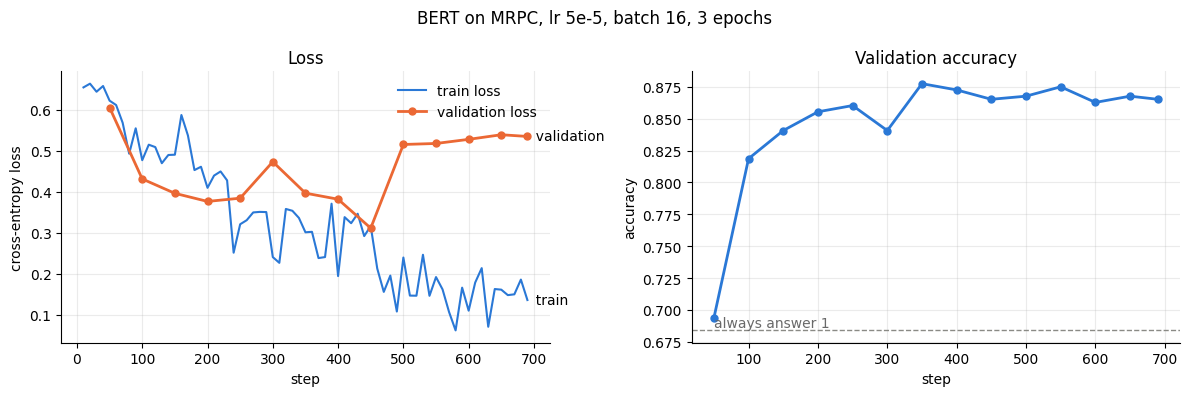

In [59]:
# 👀 Look (not in the course): plot the curves from trainer.state.log_history, the list of dicts that wandb would draw.
# Left: train and validation loss on one axis. Right: validation accuracy against the "always answer 1" baseline (0.684).
# Trainer logs no train accuracy, so the train/validation gap is read from the loss.
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"


def plot_curves(trainer, title=""):
    logs = trainer.state.log_history
    train = [(l["step"], l["loss"]) for l in logs if "loss" in l]
    evals = [(l["step"], l["eval_loss"], l["eval_accuracy"]) for l in logs if "eval_loss" in l]
    t_step, t_loss = zip(*train)
    e_step, e_loss, e_acc = zip(*evals)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(t_step, t_loss, color=BLUE, lw=1.5, label="train loss")
    ax1.plot(e_step, e_loss, color=ORANGE, lw=2, marker="o", ms=5, label="validation loss")
    ax1.text(t_step[-1], t_loss[-1], "  train", color="black", va="center")
    ax1.text(e_step[-1], e_loss[-1], "  validation", color="black", va="center")
    ax1.set(xlabel="step", ylabel="cross-entropy loss", title="Loss")
    ax1.legend(frameon=False)

    ax2.plot(e_step, e_acc, color=BLUE, lw=2, marker="o", ms=5)
    ax2.axhline(0.684, color=GRAY, lw=1, ls="--")
    ax2.text(e_step[0], 0.684, "always answer 1", color="dimgray", va="bottom")
    ax2.set(xlabel="step", ylabel="accuracy", title="Validation accuracy")

    for ax in (ax1, ax2):
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_curves(trainer, "BERT on MRPC, lr 5e-5, batch 16, 3 epochs")

### Reading the shapes

| Pattern | Train loss | Validation loss | Usual fix |
|---|---|---|---|
| **Healthy** | falls, then levels off | falls and stays close to train | nothing: it converged |
| **Overfitting** | keeps falling | stops falling, then rises | early stopping, fewer epochs, weight decay, more data |
| **Underfitting** | stays high | stays high | train longer, higher learning rate, bigger model, check the data |
| **Erratic** | jumps around, spikes | jumps around | lower learning rate, bigger batch, gradient clipping |

You already met overfitting in 3.3. Over 3 epochs, validation loss went 0.36 → 0.55 → 0.85 while accuracy held at 0.84 → 0.84 → 0.83.

How can loss triple while accuracy stays put? The loss punishes confident mistakes without limit. A wrong answer given with $p_{\text{true}} = 0.5$ costs $\ln 2 = 0.69$; with $p_{\text{true}} = 0.01$ it costs $-\ln 0.01 = 4.6$. As training goes on, the model grows more confident about everything, its mistakes included. The mean loss climbs even when the number of mistakes doesn't change.

**After a run, ask:** did it reach the baseline and beyond? Had it plateaued earlier, so fewer epochs would do? Is the train/validation gap growing? Would more steps still help?

### Early stopping

`EarlyStoppingCallback(early_stopping_patience=3)` stops training once the tracked metric (`metric_for_best_model`, here `eval_loss`) has failed to improve for 3 evaluations in a row. Here that means 3 × 100 = 300 steps, not 3 epochs. `load_best_model_at_end=True` then reloads the best checkpoint, so you keep the best model rather than the last one. That needs a checkpoint at every evaluation, which is why `save_steps` equals `eval_steps`.

The course cell uses `model`, which has already been trained by now, so load a fresh one first.

In [60]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)  # fresh model (not in the course)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [61]:
# Example of detecting overfitting with early stopping
from transformers import EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    num_train_epochs=10,  # Set high, but we'll stop early
)

# Add early stopping to prevent overfitting
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

Step,Training Loss,Validation Loss,Accuracy,F1
100,No log,0.629109,0.715686,0.827381
200,No log,0.521440,0.762255,0.847244
300,No log,0.497143,0.779412,0.855769
400,No log,0.511573,0.808824,0.872131
500,0.538990,0.468357,0.828431,0.873646
600,0.538990,0.577879,0.813725,0.876221
700,0.538990,0.569516,0.830882,0.876565
800,0.538990,0.715196,0.843137,0.890034


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

planned steps: 4590 | stopped at step: 800
best checkpoint: ./results/checkpoint-500 | best eval_loss: 0.4684


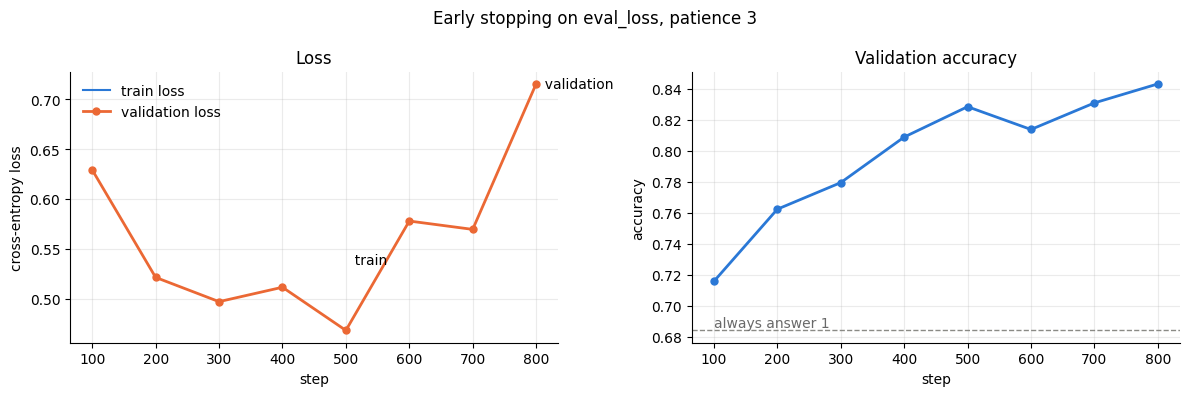

In [62]:
# 👀 Look (not in the course): the course only builds this trainer. Run it and see where it stops.
# 10 epochs x 459 steps = 4,590 planned. Checkpoints go to the runtime disk only (./results); the weights are throwaway.
out = trainer.train()
print("planned steps:", trainer.state.max_steps, "| stopped at step:", trainer.state.global_step)
print("best checkpoint:", trainer.state.best_model_checkpoint, "| best eval_loss:", round(trainer.state.best_metric, 4))
plot_curves(trainer, "Early stopping on eval_loss, patience 3")

### Underfitting and erratic curves

The page shows these two fixes as diffs (`-` old line, `+` new line), not as runnable code:

```diff
# Underfitting: train longer
-    num_train_epochs=5,
+    num_train_epochs=10,
```

```diff
# Erratic curves: "lower the learning rate and increase the batch size"
-    learning_rate=1e-5,
+    learning_rate=1e-4,
-    per_device_train_batch_size=16,
+    per_device_train_batch_size=32,
```

The second diff contradicts its own text: going from 1e-5 to 1e-4 *raises* the learning rate tenfold. The fix for erratic curves is the opposite direction.

A bigger batch steadies the curves because the gradient is a mean over the batch. Its noise (standard deviation) shrinks like $1/\sqrt{B}$, so going from 16 to 32 cuts it by about 30%.

In [63]:
# Your turn: make the curves erratic on purpose. Copy the 👀 run above (fresh model, eval every 50 steps, report_to="none"),
# add learning_rate=1e-4, train, and call plot_curves(trainer, "lr 1e-4"). Then try 5e-4.
# Predict first: what happens to train loss, and to validation accuracy relative to the "always answer 1" line?